# Where the contamination numbers come from

This notebook explains how we arrive at the radioactive contamination that is fed into SOURCES4A, and why. It replaces
the old decay-chain modeling notebook, which (together with the Mathematica notebooks) was moved to
[`archive/decay-chain-crosschecks/`](archive/decay-chain-crosschecks/README.md) because it is a cross-check rather than
an input.

**The chain of reasoning**

1. **Motivation.** In a deep underground laboratory, cosmogenic neutrons are strongly suppressed, and the neutron
   background that remains is dominated by the *radiogenic* neutrons from the walls: alpha particles from the
   $^{238}$U, $^{235}$U and $^{232}$Th decay chains in the rock and shotcrete ($\alpha$,n) reactions on the light
   nuclei of the matrix, plus spontaneous fission. The neutron source strength is proportional to how much of each
   alpha emitter is present, so we need the contamination of each material, isotope by isotope.
2. **Concentration of the head nuclide.** Measurements give the concentration of U and Th in the material. We
   express it as a mass fraction, **1 ppb = 1 ng/g** (section 1) and convert it to atoms/cm$^3$ of the chain head.
3. **The rest of the chain.** We assume *secular equilibrium*: every chain member decays as fast as it is fed. Its
   abundance relative to the head follows from half-lives and branching ratios alone (section 2).
4. **The matrix.** The target nuclei for the ($\alpha$,n) reactions are the atoms of the material, so we also need
   the composition and number density of each material (section 3).
5. **SOURCES4A inputs.** The atom densities of the alpha emitters (input card 7) and the target atom fractions
   (card 9) are exactly the outputs of sections 1 to 4. Matrix density cancels in the yield per alpha; what matters
   is the number of alpha emitters per unit volume (section 4).

The numbers in `SOURCES/analysis/decay_chains_data.xlsx` (tabs `SE (1ppb)`, `Shotcrete Density`, `Norite Density`, ...)
are the same calculations as below; the last cell of section 2 checks that this notebook reproduces them when the
workbook can be read.

In [1]:
import csv, os
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt

try:
    plt.style.use('../mplstyles/stylelib/standard.mplstyle')
except OSError:
    pass

N_A = 6.0221408e23        # Avogadro's number, 1/mol (as used in the workbook)
YEAR = 365.0              # days; the workbook converts days -> years with 365

## 1. What "1 ppb" means

In the radiopurity literature (and in the SNOLAB report behind Table I of the paper) ppm and ppb are **mass
fractions**: 1 ppb = 1 ng/g = $10^{-9}$ g of the nuclide per g of material. The number density of a nuclide of mass
number $A$ in a material of density $\rho$ is then

$$ n = \frac{c\,\rho\,N_A}{A}, \qquad c = \text{mass fraction} = 10^{-9}\ \text{per ppb}. $$

An earlier version of the workbook used a "per-atom ppb" instead ($10^{-9}$ atoms of the nuclide per atom of the
matrix). That puts $A_\mathrm{matrix}/A_\mathrm{seed}$ times too many seed atoms in the material
(about 11 times for shotcrete) and is **not** the literature definition. It is kept only for comparison.

In [2]:
def seed_density(ppb, rho_gcc, A):
    # atoms/cm^3 of a nuclide of mass number A at `ppb` ng/g in a material of density rho (g/cm^3)
    return ppb * 1e-9 * rho_gcc * N_A / A

A_TH232, A_U238 = 232.038054, 238.050788   # head-nuclide masses, amu (IAEA live chart)
U235_ABUNDANCE = 0.007204                  # atoms of U-235 per atom of U-238 in natural uranium

rho_shotcrete, rho_norite = 2.22222, 3.0   # g/cm^3 (see section 3 for where these come from)
for mat, rho in (('shotcrete', rho_shotcrete), ('norite', rho_norite)):
    print(f"{mat:9s} rho = {rho:.5f} g/cm3:  1 ppb Th-232 -> {seed_density(1, rho, A_TH232):.4e},"
          f"  1 ppb U-238 -> {seed_density(1, rho, A_U238):.4e} atoms/cm3")

shotcrete rho = 2.22222 g/cm3:  1 ppb Th-232 -> 5.7674e+12,  1 ppb U-238 -> 5.6217e+12 atoms/cm3
norite    rho = 3.00000 g/cm3:  1 ppb Th-232 -> 7.7860e+12,  1 ppb U-238 -> 7.5893e+12 atoms/cm3


## 2. Secular equilibrium from half-lives and branching ratios

With the head nuclide supplying the chain at a constant rate, each member's number $N_i$ settles where its production
equals its decay. Writing $T_i$ for the half-life and $F_i$ for the fraction of all head decays that pass through
nuclide $i$ (the product of branching ratios along the way, summed over the possible paths),

$$ \frac{N_i}{N_\mathrm{head}} = \frac{T_i}{T_\mathrm{head}}\,F_i. $$

The tables below are the decay tabs of the workbook (half-lives in years; ENSDF / NuDat 3) with the branching
ratios of each decay. The beta- and gamma-only members still matter: they are part of the chain bookkeeping even
though only the alpha emitters feed SOURCES.

In [3]:
# (nuclide, half-life in years, {daughter: fraction}); half-lives from the decay tabs of decay_chains_data.xlsx
CHAINS = {
'Th232': [
    ('Th-232', 14000000000.0, {'Ra-228': 1}),
    ('Ra-228', 5.75, {'Ac-228': 1}),
    ('Ac-228', 0.000702, {'Th-228': 1}),
    ('Th-228', 1.9125, {'Ra-224': 1}),
    ('Ra-224', 0.009950410958904109, {'Rn-220': 1}),
    ('Rn-220', 1.763064434297311e-06, {'Po-216': 1}),
    ('Po-216', 4.5662100456620995e-09, {'Pb-212': 1}),
    ('Pb-212', 0.0012146118721461188, {'Bi-212': 1}),
    ('Bi-212', 0.00011520167427701673, {'Po-212': 0.6406, 'Tl-208': 0.3594}),
    ('Po-212', 9.332191780821917e-15, {'Pb-208': 1}),
    ('Tl-208', 5.808599695585997e-06, {'Pb-208': 1}),
    ('Pb-208', None, {}),
],
'U235': [
    ('U-235', 704000000.0, {'Th-231': 1}),
    ('Th-231', 0.00291324200913242, {'Pa-231': 1}),
    ('Pa-231', 32570.0, {'Ac-227': 1}),
    ('Ac-227', 21.772, {'Th-227': 0.9862, 'Fr-223': 0.0138}),
    ('Th-227', 0.05122465753424657, {'Ra-223': 1}),
    ('Fr-223', 4.185692541856925e-05, {'Ra-223': 0.99994, 'At-219': 6e-05}),
    ('Ra-223', 0.03131506849315068, {'Rn-219': 1}),
    ('At-219', 1.7757483510908167e-06, {'Rn-219': 0.064, 'Bi-215': 0.936}),
    ('Rn-219', 1.2557077625570777e-07, {'Po-215': 1}),
    ('Bi-215', 1.445966514459665e-05, {'Po-215': 1}),
    ('Po-215', 5.647513952308472e-11, {'Pb-211': 0.9999977, 'At-215': 2.3e-06}),
    ('At-215', 3.1709791983764588e-12, {'Bi-211': 1}),
    ('Pb-211', 6.868340943683409e-05, {'Bi-211': 1}),
    ('Bi-211', 4.071537290715373e-06, {'Po-211': 0.0028, 'Tl-207': 0.9972}),
    ('Po-211', 1.6362252663622526e-08, {'Pb-207': 1}),
    ('Tl-207', 9.075342465753423e-06, {'Pb-207': 1}),
    ('Pb-207', None, {}),
],
'U238': [
    ('U-238', 4468000000.0, {'Th-234': 1}),
    ('Th-234', 0.06602739726027397, {'Pa-234m': 1}),
    ('Pa-234m', 2.2050989345509894e-06, {'U-234': 1}),
    ('U-234', 245500.0, {'Th-230': 1}),
    ('Th-230', 75400.0, {'Ra-226': 1}),
    ('Ra-226', 1600.0, {'Rn-222': 1}),
    ('Rn-222', 0.010475342465753426, {'Po-218': 1}),
    ('Po-218', 5.894216133942161e-06, {'Pb-214': 0.9998, 'At-218': 0.0002}),
    ('At-218', 4.0588533739218663e-08, {'Bi-214': 0.9995, 'Rn-218': 0.0005}),
    ('Rn-218', 1.0702054794520548e-09, {'Po-214': 1}),
    ('Pb-214', 5.148401826484018e-05, {'Bi-214': 1}),
    ('Bi-214', 3.75e-05, {'Po-214': 0.9998, 'Tl-210': 0.0002}),
    ('Po-214', 5.187721968543886e-12, {'Pb-210': 1}),
    ('Tl-210', 2.473363774733638e-06, {'Pb-210': 1}),
    ('Pb-210', 22.2, {'Bi-210': 0.999999981, 'Hg-206': 1.9e-08}),
    ('Bi-210', 0.013731506849315067, {'Po-210': 0.9999987, 'Tl-206': 1.3e-06}),
    ('Po-210', 0.3791123287671233, {'Pb-206': 1}),
    ('Hg-206', 1.582952815829528e-05, {'Tl-206': 1}),
    ('Tl-206', 7.994672754946729e-06, {'Pb-206': 1}),
    ('Pb-206', None, {}),
],
}

In [4]:
def equilibrium_ratios(chain):
    # N_i / N_head at secular equilibrium: (T_i / T_head) * F_i, F_i = fraction of head decays through i
    hl = {n: h for n, h, _ in chain}
    dau = {n: d for n, _, d in chain}
    names = [n for n, _, _ in chain]
    F = {n: 0.0 for n in names}
    F[names[0]] = 1.0
    # the chains above are listed so that a nuclide appears after everything that feeds it, except for
    # the side branches, so propagate until nothing changes
    for _ in range(len(names)):
        newF = {n: 0.0 for n in names}
        newF[names[0]] = 1.0
        for n in names:
            for d, f in dau[n].items():
                newF[d] += F[n] * f
        F = newF
    return {n: (hl[n] / hl[names[0]]) * F[n] for n in names if hl[n] is not None}, F

RATIOS = {tab: equilibrium_ratios(ch)[0] for tab, ch in CHAINS.items()}

def steady_state_linear(chain):
    # independent check: solve 0 = -lambda_i N_i + sum_j f_ji lambda_j N_j for the daughters, N_head = 1
    names = [n for n, _, _ in chain]
    lam = {n: (np.log(2) / h if h else 0.0) for n, h, _ in chain}
    idx = {n: k for k, n in enumerate(names)}
    M = np.zeros((len(names), len(names)))
    for n, _, dau in chain:
        for d, f in dau.items():
            M[idx[d], idx[n]] += f * lam[n]
        M[idx[n], idx[n]] -= lam[n]
    living = [k for k, n in enumerate(names) if lam[names[k]] > 0 and k != 0]
    A = M[np.ix_(living, living)]
    b = -M[living, 0]
    N = np.linalg.solve(A, b)
    return {names[k]: N[i] for i, k in enumerate(living)}

for tab, ch in CHAINS.items():
    lin = steady_state_linear(ch)
    worst = max(abs(lin[n] / RATIOS[tab][n] - 1) for n in lin)
    print(f"{tab}: recursion vs linear solve, worst relative difference {worst:.1e}")

Th232: recursion vs linear solve, worst relative difference 2.2e-16
U235: recursion vs linear solve, worst relative difference 7.8e-16
U238: recursion vs linear solve, worst relative difference 1.2e-15


The abundances span more than twenty orders of magnitude (the long-lived members dominate, the short-lived ones
are tiny), which is why the SOURCES inputs list them as atoms/cm$^3$ rather than in percent.

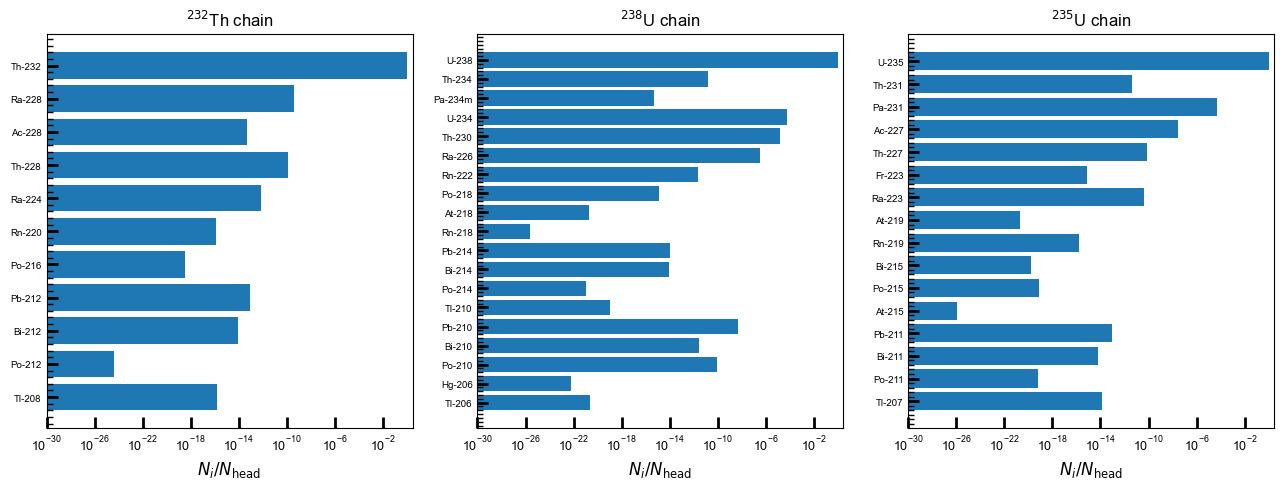

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, (tab, title) in zip(axes, (('Th232', r'$^{232}$Th chain'), ('U238', r'$^{238}$U chain'), ('U235', r'$^{235}$U chain'))):
    names = list(RATIOS[tab])
    vals = [RATIOS[tab][n] for n in names]
    ax.barh(range(len(names)), vals, color='C0')
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=7)
    ax.invert_yaxis()
    ax.set_xscale('log')
    ax.set_xlim(1e-30, 3)
    ax.set_xlabel(r'$N_i / N_\mathrm{head}$', fontsize=12)
    ax.tick_params(axis='x', labelsize=9)
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Cross-check against the workbook.** If `openpyxl` is installed (`pip install openpyxl`), the next cell reads column C of
the `SE (1ppb)` tab, which holds the same ratios as live formulas, and compares. The branching ratios in the workbook
are typed to a few digits, so agreement to about $10^{-4}$ or better is expected; a bigger difference points at a typo
in one of the two.

For the record: an independent ODE solution (Mathematica) agrees with the workbook to 0.55 % for U-235, limited by the
rounded decay constants hard-coded in those notebooks; they are archived in
[`archive/decay-chain-crosschecks/`](archive/decay-chain-crosschecks/README.md).

In [6]:
Z = {'Tl': 81, 'Pb': 82, 'Bi': 83, 'Po': 84, 'At': 85, 'Rn': 86, 'Fr': 87, 'Ra': 88, 'Ac': 89, 'Th': 90, 'Pa': 91, 'U': 92, 'Hg': 80}

def code_of(name):          # 'Bi-212' -> '832120' (SOURCES style: Z*10000 + A*10)
    el, a = name.split('-')
    return str(Z[el] * 10000 + int(a.rstrip('m')) * 10)

WORKBOOK = 'SOURCES/analysis/decay_chains_data.xlsx'
try:
    import openpyxl
    ws = openpyxl.load_workbook(WORKBOOK, data_only=True)['SE (1ppb)']
    book = {}
    for row in ws.iter_rows(min_col=1, max_col=3, values_only=True):
        if isinstance(row[0], str) and row[0][:6].isdigit() and isinstance(row[2], (int, float)):
            book[row[0][:6]] = row[2]
    mine = {code_of(n): v for tab in RATIOS for n, v in RATIOS[tab].items()}
    # the U-235 head row is the U-235 head itself (ratio 1) and appears once per block
    rows = [(c, v, mine[c]) for c, v in book.items() if c in mine]
    worst = max(rows, key=lambda r: abs(r[2] / r[1] - 1))
    print(f"{len(rows)} workbook rows compared; worst relative difference {abs(worst[2]/worst[1]-1):.1e} at {worst[0]}")
    for c, wbv, nbv in rows:
        if abs(nbv / wbv - 1) > 1e-4:
            print(f"  {c}: workbook {wbv:.5e}, notebook {nbv:.5e}")
except ImportError:
    print('openpyxl not installed; skipping the workbook cross-check')
except (OSError, KeyError) as err:
    print('could not read the workbook:', err)

32 workbook rows compared; worst relative difference 1.7e-06 at 842110


## 3. The materials: composition, density and number density

The ($\alpha$,n) targets are the atoms of the material around the detector. Two materials matter for the paper:

* **Shotcrete**, the sprayed-concrete lining of the cavern. Composition: SNOLAB-STR-2007-003 (I. T. Lawson, 2007),
  Table 3, shotcrete column (sample 15, product MS-D3). The density, 2222.22 kg/m$^3$, is 1000 kg per 0.45 m$^3$
  from the Sika King MS-D3 datasheet; it is not in the report. The report's composition sums to 99.66 % (the rest is
  trace elements).
* **Norite**, the host rock. A 50:50 mix by volume of orthopyroxene (3.3 g/cm$^3$) and plagioclase (2.7 g/cm$^3$),
  with the GEOROC mean oxide weight percents used in `C-Slab-Source-and-Shielding.ipynb`. Iron is counted once,
  as FeOT. The inputs use 3.0 g/cm$^3$; the oxide table implies 3.05.

The **number density** of an element is $n = \rho\,w\,N_A/M$ with $w$ the mass fraction, and the **target atom
fraction** (SOURCES card 9) is $n/\sum n$.

In [7]:
# shotcrete: SNOLAB-STR-2007-003 Table 3, mass percent and molar mass (amu)
SHOTCRETE = {'Al': (6.04, 26.981539), 'Ca': (9.54, 40.078), 'Fe': (2.54, 55.845), 'K': (1.76, 39.0983),
             'Mg': (1.18, 24.305), 'Mn': (0.37, 54.938044), 'Na': (2.25, 22.989769), 'Si': (27.9, 28.0855),
             'H': (0.04, 1.00784), 'C': (0.04, 12.011), 'O': (48.0, 15.999)}

def number_densities(table, rho):
    return {el: rho * (w / 100.0) * N_A / M for el, (w, M) in table.items()}

n_shot = number_densities(SHOTCRETE, rho_shotcrete)
n_shot_tot = sum(n_shot.values())
print(f"shotcrete: sum of mass percent {sum(w for w, _ in SHOTCRETE.values()):.2f}, total number density {n_shot_tot:.4e} atoms/cm3")
for el, n in sorted(n_shot.items(), key=lambda kv: -kv[1]):
    print(f"  {el:2s} {n:.4e} cm^-3  atom fraction {n / n_shot_tot:.5f}")

# norite: number densities from the table that the SOURCES norite inputs were built from
with open('SOURCES/norite/inputs/composition.csv') as f:
    norite = {r['element']: float(r['number_density_per_cm3']) for r in csv.DictReader(f)}
n_nor_tot = sum(norite.values())
print(f"\nnorite: total number density {n_nor_tot:.4e} atoms/cm3 (from composition.csv)")

shotcrete: sum of mass percent 99.66, total number density 6.3462e+22 atoms/cm3
  O  4.0150e+22 cm^-3  atom fraction 0.63266
  Si 1.3294e+22 cm^-3  atom fraction 0.20948
  Ca 3.1855e+21 cm^-3  atom fraction 0.05020
  Al 2.9958e+21 cm^-3  atom fraction 0.04721
  Na 1.3097e+21 cm^-3  atom fraction 0.02064
  Mg 6.4972e+20 cm^-3  atom fraction 0.01024
  Fe 6.0868e+20 cm^-3  atom fraction 0.00959
  K  6.0241e+20 cm^-3  atom fraction 0.00949
  H  5.3114e+20 cm^-3  atom fraction 0.00837
  Mn 9.0129e+19 cm^-3  atom fraction 0.00142
  C  4.4568e+19 cm^-3  atom fraction 0.00070

norite: total number density 8.4713e+22 atoms/cm3 (from composition.csv)


## 4. Putting it together: atoms/cm$^3$ per ppb, and for the measured concentrations

The SOURCES inputs are written **per 1 ppb of the head nuclide**, so the neutron yield can be scaled to any measured
concentration afterwards. Natural uranium is $^{238}$U with $^{235}$U locked to it by the natural abundance
(0.7204 % by atoms), so one U concentration sets both chains.

The measured concentrations used in the paper come from SNOLAB-STR-2007-003: **shotcrete 15.24 ppm Th and 2.46 ppm U**
(Table I of the paper), and for the norite the rock averages of the same report, **5.56 ppm Th and 1.11 ppm U** (Table 1,
from $^{228}$Th and $^{226}$Ra). Other sources disagree for the norite (see the open questions below).

In [8]:
def head_densities(rho, th_ppb=1.0, u_ppb=1.0):
    n_th232 = seed_density(th_ppb, rho, A_TH232)
    n_u238 = seed_density(u_ppb, rho, A_U238)
    return {'Th232': n_th232, 'U238': n_u238, 'U235': U235_ABUNDANCE * n_u238}

print('head nuclide, atoms/cm3 per 1 ppb:')
for mat, rho in (('shotcrete', rho_shotcrete), ('norite', rho_norite)):
    h = head_densities(rho)
    print(f"  {mat:9s} Th-232 {h['Th232']:.4e}   U-238 {h['U238']:.4e}   U-235 {h['U235']:.4e}")

measured = {'shotcrete': (rho_shotcrete, 15240.0, 2460.0), 'norite': (rho_norite, 5560.0, 1110.0)}
print('\nalpha emitters at the measured concentrations (atoms/cm3), first rows of each chain:')
for mat, (rho, th_ppb, u_ppb) in measured.items():
    h = head_densities(rho, th_ppb, u_ppb)
    print(f"{mat}: Th-232 {h['Th232']:.3e}, U-238 {h['U238']:.3e}, U-235 {h['U235']:.3e}")
    for tab in ('Th232', 'U238', 'U235'):
        top = sorted(RATIOS[tab].items(), key=lambda kv: -kv[1])[:4]
        print('   ' + tab + ': ' + ', '.join(f"{n} {r * h[tab]:.2e}" for n, r in top))

head nuclide, atoms/cm3 per 1 ppb:
  shotcrete Th-232 5.7674e+12   U-238 5.6217e+12   U-235 4.0499e+10
  norite    Th-232 7.7860e+12   U-238 7.5893e+12   U-235 5.4673e+10

alpha emitters at the measured concentrations (atoms/cm3), first rows of each chain:
shotcrete: Th-232 8.789e+16, U-238 1.383e+16, U-235 9.963e+13
   Th232: Th-232 8.79e+16, Ra-228 3.61e+07, Th-228 1.20e+07, Ra-224 6.25e+04
   U238: U-238 1.38e+16, U-234 7.60e+11, Th-230 2.33e+11, Ra-226 4.95e+09
   U235: U-235 9.96e+13, Pa-231 4.61e+09, Ac-227 3.08e+06, Th-227 7.15e+03
norite: Th-232 4.329e+16, U-238 8.424e+15, U-235 6.069e+13
   Th232: Th-232 4.33e+16, Ra-228 1.78e+07, Th-228 5.91e+06, Ra-224 3.08e+04
   U238: U-238 8.42e+15, U-234 4.63e+11, Th-230 1.42e+11, Ra-226 3.02e+09
   U235: U-235 6.07e+13, Pa-231 2.81e+09, Ac-227 1.88e+06, Th-227 4.35e+03


**The per-atom reading, for comparison.** Reading 15.24 ppm as $15.24\times10^{-6}$ atoms of Th per atom of shotcrete
would give

In [9]:
per_atom = 15.24e-6 * n_shot_tot
by_mass = head_densities(rho_shotcrete, 15240.0, 0)['Th232']
print(f"Th-232 in shotcrete: by mass {by_mass:.3e} atoms/cm3; per atom {per_atom:.3e} ({per_atom / by_mass:.1f} times more)")

Th-232 in shotcrete: by mass 8.789e+16 atoms/cm3; per atom 9.672e+17 (11.0 times more)


## 5. Caveats and open questions

* **Norite concentrations.** Three sources disagree: the SNOLAB User's Handbook (3.3 ppm Th, 1.2 ppm U), the 2007
  report rock averages used above (5.56 ppm Th, 1.11 ppm U) and Layne Hellman's composition work. The neutron
  rate scales linearly with these.
* **Shotcrete density and water.** The density comes from a dry-mix yield; the shotcrete as shot holds 8.6 to 10.8 %
  water. The workbook has an input for the retained water fraction (default 0). With ppm per dry mass the ng/g results
  do not change, only the target fractions do.
* **Secular equilibrium** is an assumption. Radon emanation or a disturbed chain (for example $^{226}$Ra against
  $^{238}$U) would break it; the report measures U from $^{226}$Ra and Th from $^{228}$Th.
* **Trace elements** (P, Ti, Cr, Ni in the norite) have no CIAAW isotopic-abundance bounds yet.
* The workbook, its history and its status per tab are documented in
  [`SOURCES/analysis/decay_chains_data_README.md`](SOURCES/analysis/decay_chains_data_README.md) and
  [`changelog.md`](SOURCES/analysis/changelog.md).

Next: [`B-SOURCES4A-Running.ipynb`](B-SOURCES4A-Running.ipynb) runs SOURCES with these inputs.